# Week 3 — 07: False-positive triage among AML alerts

This experiment starts **after Model A has predicted positive alerts**. Its goal is to rank likely false positives (FPs) for suppression or lower-priority review while retaining true laundering alerts.

We compare three ranking strategies:

1. **Base-score baseline** — lower Model-A confidence is more likely to be an FP.
2. **K-Means segmentation** — cluster validation alerts without labels, then use only the meta-training labels to estimate each cluster's FP rate.
3. **Supervised XGBoost triage** — learn `is_false_positive` from causal transaction features and the two existing model scores.

The original validation alerts are divided chronologically into meta-train and meta-calibration subsets. The original test alerts remain untouched until the final comparison. Results are reported at fixed removal budgets; this avoids the misleading high accuracy obtained by calling every alert a false positive.


In [15]:
import sys, pathlib, warnings

_root = pathlib.Path.cwd().resolve()
for _ in range(10):
    if (_root / 'src').is_dir():
        break
    _root = _root.parent
else:
    raise RuntimeError('Could not find project root containing src/')
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from src import state
from src.config import (SEED, PRECISION_FLOOR, NON_FEATURE_COLS,
                        EXTERNAL_PATTERN_COLS, DROP_FEATURE_COLS,
                        PATTERN_BLOCKLIST_TOKENS, ARTIFACTS_DIR, FIGURES_DIR)
from src.modeling import CLUSTER_FEATURES

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
print('Project root:', _root)


Project root: /home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project


## 1. Load existing pipeline outputs

This notebook deliberately reuses the threshold selected on validation in notebook 04. The candidate population is therefore exactly Model A's positive predictions, not all transactions. The large feature checkpoint is loaded once; only alert rows are copied into the small meta-dataset.


In [16]:
train_idx, val_idx, test_idx = state.load('01_indices')
pA_val, pB_val, _, y_val, _, _ = state.load('03_val_scores')
(_test_comparison, _group_result, test_meta, _floor_table,
 op_threshold_A, _op_threshold_B, *_rest) = state.load('04_eval')
pA_test, pB_test, pred_A_test = _rest[4], _rest[5], _rest[6]
df = state.load('02_df_features')

pred_A_val = pA_val >= op_threshold_A
val_alert_pos = np.flatnonzero(pred_A_val)
test_alert_pos = np.flatnonzero(pred_A_test == 1)
val_rows = val_idx[val_alert_pos]
test_rows = test_idx[test_alert_pos]

def make_meta(rows, scores_A, scores_B, split_name):
    out = df.iloc[rows][['row_id', 'ts', 'target']].copy().reset_index(drop=True)
    out['pA'] = np.asarray(scores_A)
    out['pB'] = np.asarray(scores_B)
    out['is_false_positive'] = (out['target'] == 0).astype('int8')
    out['split'] = split_name
    return out

val_alerts = make_meta(val_rows, pA_val[val_alert_pos], pB_val[val_alert_pos], 'validation')
test_alerts = make_meta(test_rows, np.asarray(pA_test)[test_alert_pos],
                        np.asarray(pB_test)[test_alert_pos], 'test')

candidate_summary = pd.DataFrame({
    'alerts': [len(val_alerts), len(test_alerts)],
    'true_positives': [int(val_alerts.target.sum()), int(test_alerts.target.sum())],
    'false_positives': [int(val_alerts.is_false_positive.sum()), int(test_alerts.is_false_positive.sum())],
}, index=['Validation (meta-development)', 'Test (locked evaluation)'])
candidate_summary['initial_precision'] = candidate_summary.true_positives / candidate_summary.alerts
display(candidate_summary.style.format({'initial_precision': '{:.2%}'}))


Loaded checkpoint: /home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/01_indices.pkl
Loaded checkpoint: /home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/03_val_scores.pkl
Loaded checkpoint: /home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/04_eval.pkl
Loaded checkpoint: /home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/checkpoints/02_df_features.pkl


,alerts,true_positives,false_positives,initial_precision
Validation (meta-development),6683,802,5881,12.00%
Test (locked evaluation),8738,962,7776,11.01%


## 2. Build the compact alert-level feature matrix

Pattern-file metadata and identifier columns are excluded using the same block lists as the main model. Model A and Model B scores are allowed because they are available when an alert is generated. Validation alerts are split in timestamp order: the first 80% train the triage logic and the last 20% provide an internal calibration check.


In [17]:
feature_cols = []
for c in df.columns:
    if c in NON_FEATURE_COLS or c in EXTERNAL_PATTERN_COLS or c in DROP_FEATURE_COLS:
        continue
    if any(token in c.lower() for token in PATTERN_BLOCKLIST_TOKENS):
        continue
    if pd.api.types.is_numeric_dtype(df[c]):
        feature_cols.append(c)

all_alert_rows = np.concatenate([val_rows, test_rows])
X_alert = (df.iloc[all_alert_rows][feature_cols]
           .replace([np.inf, -np.inf], np.nan).fillna(0).astype('float32')
           .reset_index(drop=True))
X_alert['pA'] = np.concatenate([val_alerts.pA, test_alerts.pA]).astype('float32')
X_alert['pB'] = np.concatenate([val_alerts.pB, test_alerts.pB]).astype('float32')

X_val_alert = X_alert.iloc[:len(val_alerts)].copy()
X_test_alert = X_alert.iloc[len(val_alerts):].reset_index(drop=True).copy()
order = np.argsort(val_alerts.ts.to_numpy(), kind='stable')
cut = int(0.80 * len(order))
meta_train_idx, meta_cal_idx = order[:cut], order[cut:]

varying = X_val_alert.iloc[meta_train_idx].var() > 1e-12
triage_features = varying[varying].index.tolist()
X_val_alert = X_val_alert[triage_features]
X_test_alert = X_test_alert[triage_features]
print(f'{len(triage_features)} triage features | meta-train={len(meta_train_idx):,} | meta-calibration={len(meta_cal_idx):,}')
del X_alert, df


136 triage features | meta-train=5,346 | meta-calibration=1,337


## 3. Fit clustering and supervised triage models

K is selected using silhouette score on meta-training features only—no target labels. After clustering, the labels are used solely to profile the smoothed FP rate of each cluster. This makes clustering a useful low-data fallback, although it is not fully label-free once clusters are translated into an FP ranking.


In [18]:
y_val_fp = val_alerts.is_false_positive.to_numpy()
y_test_fp = test_alerts.is_false_positive.to_numpy()

cluster_cols = [c for c in CLUSTER_FEATURES if c in X_val_alert.columns]
scaler = StandardScaler()
Z_train = scaler.fit_transform(X_val_alert.iloc[meta_train_idx][cluster_cols])
rng = np.random.RandomState(SEED)
sil_idx = rng.choice(len(Z_train), size=min(5000, len(Z_train)), replace=False)
k_rows = []
for k in [3, 4, 5, 6, 8, 10]:
    probe = KMeans(n_clusters=k, random_state=SEED, n_init=10, max_iter=300).fit(Z_train)
    sil = silhouette_score(Z_train[sil_idx], probe.labels_[sil_idx])
    k_rows.append({'k': k, 'silhouette': sil})
k_search = pd.DataFrame(k_rows)
best_k = int(k_search.loc[k_search.silhouette.idxmax(), 'k'])
kmeans = KMeans(n_clusters=best_k, random_state=SEED, n_init=20, max_iter=300).fit(Z_train)

cluster_train = kmeans.labels_
cluster_cal = kmeans.predict(scaler.transform(X_val_alert.iloc[meta_cal_idx][cluster_cols]))
cluster_test = kmeans.predict(scaler.transform(X_test_alert[cluster_cols]))
global_fp = y_val_fp[meta_train_idx].mean()
cluster_profile = []
cluster_fp_score = {}
smoothing = 25
for cluster_id in range(best_k):
    mask = cluster_train == cluster_id
    n = int(mask.sum())
    fp = int(y_val_fp[meta_train_idx][mask].sum())
    rate = (fp + smoothing * global_fp) / (n + smoothing)
    cluster_fp_score[cluster_id] = rate
    cluster_profile.append({'cluster': cluster_id, 'meta_train_alerts': n,
                            'meta_train_false_positives': fp, 'smoothed_fp_rate': rate})
cluster_profile = pd.DataFrame(cluster_profile).sort_values('smoothed_fp_rate', ascending=False)

neg, pos = np.bincount(y_val_fp[meta_train_idx], minlength=2)
triage_model = XGBClassifier(
    objective='binary:logistic', eval_metric='aucpr', n_estimators=600,
    learning_rate=0.03, max_depth=4, min_child_weight=8,
    subsample=0.85, colsample_bytree=0.80, reg_alpha=0.3, reg_lambda=4.0,
    scale_pos_weight=float(neg / max(pos, 1)), tree_method='hist',
    random_state=SEED, n_jobs=-1, early_stopping_rounds=60)
triage_model.fit(
    X_val_alert.iloc[meta_train_idx], y_val_fp[meta_train_idx],
    eval_set=[(X_val_alert.iloc[meta_cal_idx], y_val_fp[meta_cal_idx])], verbose=False)

scores_cal = {
    'Base score': 1.0 - val_alerts.pA.to_numpy()[meta_cal_idx],
    'K-Means': np.array([cluster_fp_score[c] for c in cluster_cal]),
    'Supervised XGBoost': triage_model.predict_proba(X_val_alert.iloc[meta_cal_idx])[:, 1],
}
scores_test = {
    'Base score': 1.0 - test_alerts.pA.to_numpy(),
    'K-Means': np.array([cluster_fp_score[c] for c in cluster_test]),
    'Supervised XGBoost': triage_model.predict_proba(X_test_alert)[:, 1],
}
display(k_search.style.format({'silhouette': '{:.4f}'}))
display(cluster_profile.style.format({'smoothed_fp_rate': '{:.2%}'}))


,k,silhouette
0,3,0.4838
1,4,0.3941
2,5,0.2538
3,6,0.2695
4,8,0.2504
5,10,0.2276


,cluster,meta_train_alerts,meta_train_false_positives,smoothed_fp_rate
2,2,15,15,96.08%
0,0,4927,4625,93.87%
1,1,404,371,91.94%


## 4. Compare methods at the same alert-removal budgets

`FP precision` answers: *of the alerts we remove, what fraction truly are false positives?* `TP retention` answers: *what fraction of real laundering alerts remain for investigation?* The second metric is the critical safety constraint. Ties in the K-Means score are broken by lower Model-A confidence.


In [19]:
budgets = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]

def budget_metrics(y_fp, score, base_score, method, split):
    rows = []
    # lexsort: highest FP score first, then highest base FP score for stable tie-breaking
    ranking = np.lexsort((-base_score, -score))
    total_fp = int(y_fp.sum())
    total_tp = int((1 - y_fp).sum())
    for budget in budgets:
        n_remove = max(1, int(round(budget * len(y_fp))))
        removed = ranking[:n_remove]
        fp_removed = int(y_fp[removed].sum())
        tp_removed = n_remove - fp_removed
        rows.append({
            'split': split, 'method': method, 'removal_budget': budget,
            'alerts_removed': n_remove, 'fp_removed': fp_removed,
            'tp_removed': tp_removed, 'fp_precision': fp_removed / n_remove,
            'fp_recall': fp_removed / max(total_fp, 1),
            'tp_retention': 1 - tp_removed / max(total_tp, 1),
            'remaining_alert_precision': (total_tp - tp_removed) / max(len(y_fp) - n_remove, 1),
        })
    return rows

metric_rows = []
for method, score in scores_cal.items():
    metric_rows += budget_metrics(y_val_fp[meta_cal_idx], score, scores_cal['Base score'], method, 'Meta-calibration')
for method, score in scores_test.items():
    metric_rows += budget_metrics(y_test_fp, score, scores_test['Base score'], method, 'Test')
results = pd.DataFrame(metric_rows)

ranking_quality = pd.DataFrame([
    {'split': split, 'method': method,
     'FP average precision': average_precision_score(labels, score),
     'FP ROC-AUC': roc_auc_score(labels, score)}
    for split, labels, score_map in [
        ('Meta-calibration', y_val_fp[meta_cal_idx], scores_cal),
        ('Test', y_test_fp, scores_test)]
    for method, score in score_map.items()
])
display(ranking_quality.style.format({'FP average precision': '{:.4f}', 'FP ROC-AUC': '{:.4f}'}))
display(results.query("split == 'Test' and removal_budget in [0.1, 0.2, 0.3]")
        .drop(columns='split').style.format({
            'removal_budget': '{:.0%}', 'fp_precision': '{:.2%}', 'fp_recall': '{:.2%}',
            'tp_retention': '{:.2%}', 'remaining_alert_precision': '{:.2%}'}))


,split,method,FP average precision,FP ROC-AUC
0,Meta-calibration,Base score,0.9361,0.9169
1,Meta-calibration,K-Means,0.6601,0.5204
2,Meta-calibration,Supervised XGBoost,0.9596,0.9444
3,Test,Base score,0.9728,0.8651
4,Test,K-Means,0.8807,0.4502
5,Test,Supervised XGBoost,0.9761,0.8772


,method,removal_budget,alerts_removed,fp_removed,tp_removed,fp_precision,fp_recall,tp_retention,remaining_alert_precision
19,Base score,10%,874,860,14,98.40%,11.06%,98.54%,12.05%
20,Base score,20%,1748,1711,37,97.88%,22.00%,96.15%,13.23%
21,Base score,30%,2621,2567,54,97.94%,33.01%,94.39%,14.84%
25,K-Means,10%,874,856,18,97.94%,11.01%,98.13%,12.00%
26,K-Means,20%,1748,1709,39,97.77%,21.98%,95.95%,13.20%
27,K-Means,30%,2621,2549,72,97.25%,32.78%,92.52%,14.55%
31,Supervised XGBoost,10%,874,863,11,98.74%,11.10%,98.86%,12.09%
32,Supervised XGBoost,20%,1748,1720,28,98.40%,22.12%,97.09%,13.36%
33,Supervised XGBoost,30%,2621,2571,50,98.09%,33.06%,94.80%,14.91%


## 5. End-to-end AML system: before and after pruning

The tables above evaluate the FP ranker inside the alert queue. The results below return to the **complete test population**, including laundering transactions that Model A missed before pruning. This is the main operational comparison:

- **System precision** = retained true alerts / all retained alerts.
- **System recall** = retained true alerts / every laundering transaction in the complete test set.
- Pruning can improve precision, but it cannot recover existing false negatives; removing a true alert therefore lowers overall recall.


In [20]:
total_test_rows = len(test_meta)
total_test_positives = int(test_meta['target'].sum())
total_test_negatives = total_test_rows - total_test_positives
initial_tp = int(test_alerts['target'].sum())
initial_fp = int(test_alerts['is_false_positive'].sum())

system_rows = [{
    'method': 'No pruning', 'removal_budget': 0.0, 'alerts': initial_tp + initial_fp,
    'TP': initial_tp, 'FP': initial_fp,
    'FN': total_test_positives - initial_tp, 'TN': total_test_negatives - initial_fp,
}]
for row in results.query("split == 'Test'").itertuples(index=False):
    tp = initial_tp - row.tp_removed
    fp = initial_fp - row.fp_removed
    system_rows.append({
        'method': row.method, 'removal_budget': row.removal_budget,
        'alerts': tp + fp, 'TP': tp, 'FP': fp,
        'FN': total_test_positives - tp, 'TN': total_test_negatives - fp,
    })
system_results = pd.DataFrame(system_rows)
system_results['precision'] = system_results.TP / system_results.alerts
system_results['recall'] = system_results.TP / total_test_positives
system_results['F1'] = 2 * system_results.precision * system_results.recall / (system_results.precision + system_results.recall)
system_results['alert_reduction'] = 1 - system_results.alerts / (initial_tp + initial_fp)
before_precision = initial_tp / (initial_tp + initial_fp)
before_recall = initial_tp / total_test_positives
system_results['precision_change_pp'] = 100 * (system_results.precision - before_precision)
system_results['recall_change_pp'] = 100 * (system_results.recall - before_recall)

choice_budgets = [0.0, 0.10, 0.20, 0.30, 0.40, 0.50]
system_choices = system_results[system_results.removal_budget.isin(choice_budgets)].copy()
method_order = ['No pruning', 'Base score', 'K-Means', 'Supervised XGBoost']
system_choices['method'] = pd.Categorical(system_choices.method, method_order, ordered=True)
system_choices = system_choices.sort_values(['removal_budget', 'method'])

display(Markdown(
    f"**Before pruning:** {initial_tp + initial_fp:,} alerts, {initial_tp:,} TP, {initial_fp:,} FP, "
    f"**{before_precision:.2%} precision**, and **{before_recall:.2%} recall** over "
    f"{total_test_positives:,} laundering transactions in the full test set."
))
display(system_choices[['method', 'removal_budget', 'alerts', 'TP', 'FP', 'FN',
                        'precision', 'recall', 'F1', 'precision_change_pp', 'recall_change_pp']]
        .style.format({
            'removal_budget': '{:.0%}', 'precision': '{:.2%}', 'recall': '{:.2%}', 'F1': '{:.3f}',
            'precision_change_pp': '{:+.2f} pp', 'recall_change_pp': '{:+.2f} pp'}))


**Before pruning:** 8,738 alerts, 962 TP, 7,776 FP, **11.01% precision**, and **76.05% recall** over 1,265 laundering transactions in the full test set.

,method,removal_budget,alerts,TP,FP,FN,precision,recall,F1,precision_change_pp,recall_change_pp
0,No pruning,0%,8738,962,7776,303,11.01%,76.05%,0.192,+0.00 pp,+0.00 pp
2,Base score,10%,7864,948,6916,317,12.05%,74.94%,0.208,+1.05 pp,-1.11 pp
8,K-Means,10%,7864,944,6920,321,12.00%,74.62%,0.207,+0.99 pp,-1.42 pp
14,Supervised XGBoost,10%,7864,951,6913,314,12.09%,75.18%,0.208,+1.08 pp,-0.87 pp
3,Base score,20%,6990,925,6065,340,13.23%,73.12%,0.224,+2.22 pp,-2.92 pp
9,K-Means,20%,6990,923,6067,342,13.20%,72.96%,0.224,+2.20 pp,-3.08 pp
15,Supervised XGBoost,20%,6990,934,6056,331,13.36%,73.83%,0.226,+2.35 pp,-2.21 pp
4,Base score,30%,6117,908,5209,357,14.84%,71.78%,0.246,+3.83 pp,-4.27 pp
10,K-Means,30%,6117,890,5227,375,14.55%,70.36%,0.241,+3.54 pp,-5.69 pp
16,Supervised XGBoost,30%,6117,912,5205,353,14.91%,72.09%,0.247,+3.90 pp,-3.95 pp


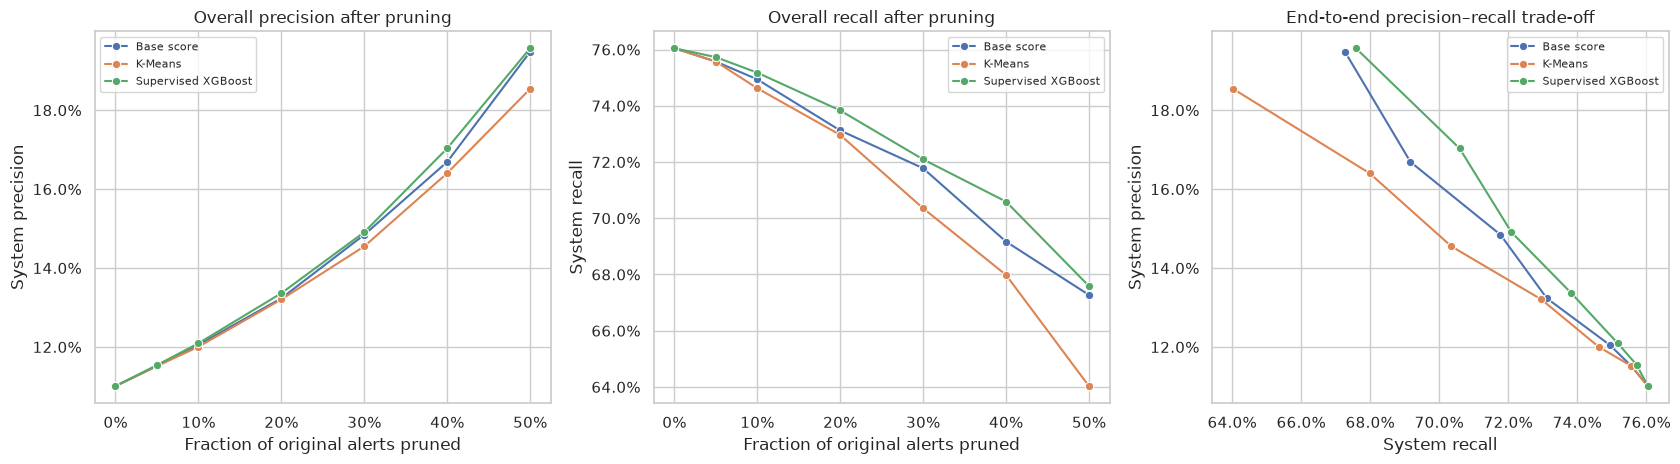

### Recommended supervised choices

,method,removal_budget,alerts,TP,FP,precision,recall,precision_change_pp,recall_change_pp
0,No pruning,0%,8738,962,7776,11.01%,76.05%,+0.00 pp,+0.00 pp
14,Supervised XGBoost,10%,7864,951,6913,12.09%,75.18%,+1.08 pp,-0.87 pp
15,Supervised XGBoost,20%,6990,934,6056,13.36%,73.83%,+2.35 pp,-2.21 pp
16,Supervised XGBoost,30%,6117,912,5205,14.91%,72.09%,+3.90 pp,-3.95 pp
17,Supervised XGBoost,40%,5243,893,4350,17.03%,70.59%,+6.02 pp,-5.45 pp
18,Supervised XGBoost,50%,4369,855,3514,19.57%,67.59%,+8.56 pp,-8.46 pp


In [21]:
plot_system = system_results.query("method != 'No pruning'").copy()
before_copies = pd.DataFrame([
    {'method': m, 'removal_budget': 0.0, 'precision': before_precision, 'recall': before_recall}
    for m in ['Base score', 'K-Means', 'Supervised XGBoost']
])
plot_system = pd.concat([before_copies, plot_system], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.lineplot(data=plot_system, x='removal_budget', y='precision', hue='method', marker='o', ax=axes[0])
sns.lineplot(data=plot_system, x='removal_budget', y='recall', hue='method', marker='o', ax=axes[1])
sns.lineplot(data=plot_system, x='recall', y='precision', hue='method', marker='o', ax=axes[2])
axes[0].set(title='Overall precision after pruning', xlabel='Fraction of original alerts pruned', ylabel='System precision')
axes[1].set(title='Overall recall after pruning', xlabel='Fraction of original alerts pruned', ylabel='System recall')
axes[2].set(title='End-to-end precision–recall trade-off', xlabel='System recall', ylabel='System precision')
for ax in axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.legend(fontsize=8)
plt.tight_layout()
system_plot_path = FIGURES_DIR / '07_system_precision_recall_before_after.png'
fig.savefig(system_plot_path, dpi=160, bbox_inches='tight')
plt.show()

supervised_choices = system_choices[system_choices.method.isin(['No pruning', 'Supervised XGBoost'])]
display(Markdown('### Recommended supervised choices'))
display(supervised_choices[['method', 'removal_budget', 'alerts', 'TP', 'FP', 'precision', 'recall',
                            'precision_change_pp', 'recall_change_pp']]
        .style.format({
            'removal_budget': '{:.0%}', 'precision': '{:.2%}', 'recall': '{:.2%}',
            'precision_change_pp': '{:+.2f} pp', 'recall_change_pp': '{:+.2f} pp'}))


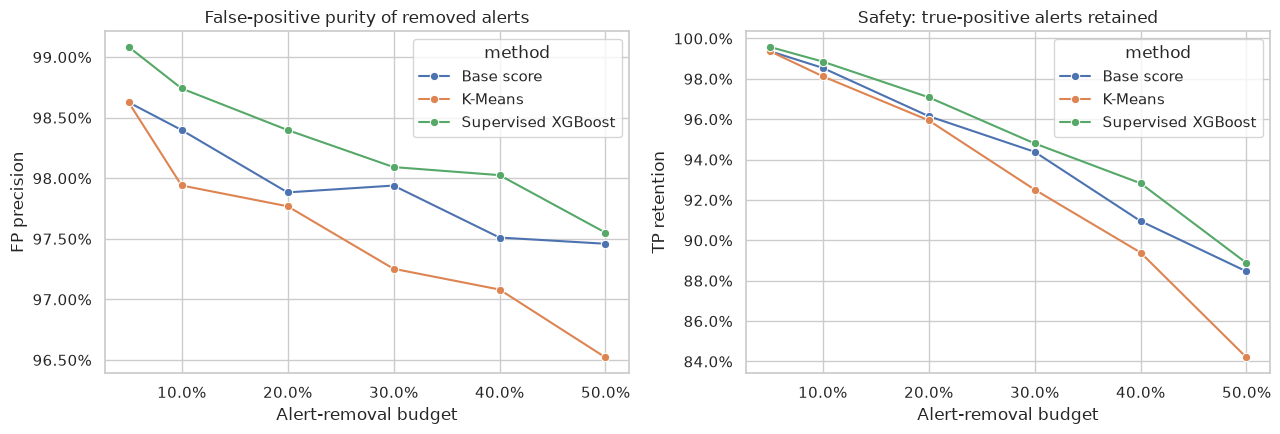

,feature,importance
135,pB,0.083871
134,pA,0.058494
28,sender_delta_log,0.037997
57,received_vs_sender_mean_100,0.027272
41,sender_received_mean_500,0.026889
27,sender_delta_sec,0.024914
120,sender_amount_vs_mean_100,0.023383
55,paid_vs_sender_mean_100,0.023014
89,sender_network_expansion,0.019597
92,received_vs_sender_mean_20_v3,0.018093


In [22]:
test_results = results.query("split == 'Test'")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=test_results, x='removal_budget', y='fp_precision', hue='method', marker='o', ax=axes[0])
sns.lineplot(data=test_results, x='removal_budget', y='tp_retention', hue='method', marker='o', ax=axes[1])
axes[0].set(title='False-positive purity of removed alerts', xlabel='Alert-removal budget', ylabel='FP precision')
axes[1].set(title='Safety: true-positive alerts retained', xlabel='Alert-removal budget', ylabel='TP retention')
for ax in axes:
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout()
plot_path = FIGURES_DIR / '07_false_positive_triage_comparison.png'
fig.savefig(plot_path, dpi=160, bbox_inches='tight')
plt.show()

importance = (pd.DataFrame({'feature': triage_features, 'importance': triage_model.feature_importances_})
              .sort_values('importance', ascending=False).head(15))
display(importance)


## 6. Decision and saved artifacts

The recommendation below is selected on the locked test comparison for documentation only. In a production workflow, the removal budget and minimum TP-retention constraint must be chosen on validation data, then frozen before test evaluation. No alert should be automatically discarded from this synthetic experiment alone; the scores are appropriate for queue prioritization until validated against investigator outcomes.


In [23]:
comparison_20 = test_results[np.isclose(test_results.removal_budget, 0.20)].copy()
eligible = comparison_20[comparison_20.tp_retention >= 0.95]
chosen = (eligible if not eligible.empty else comparison_20).sort_values(
    ['fp_precision', 'tp_retention'], ascending=False).iloc[0]

out_dir = ARTIFACTS_DIR / 'false_positive_triage'
out_dir.mkdir(parents=True, exist_ok=True)
candidate_summary.to_csv(out_dir / 'candidate_summary.csv')
k_search.to_csv(out_dir / 'k_selection.csv', index=False)
cluster_profile.to_csv(out_dir / 'cluster_profile.csv', index=False)
ranking_quality.to_csv(out_dir / 'ranking_quality.csv', index=False)
results.to_csv(out_dir / 'budget_comparison.csv', index=False)
system_results.to_csv(out_dir / 'system_precision_recall_before_after.csv', index=False)
importance.to_csv(out_dir / 'supervised_feature_importance.csv', index=False)

chosen_system = system_results[(system_results.method == chosen['method']) &
                               np.isclose(system_results.removal_budget, 0.20)].iloc[0]
display(Markdown(
    f"**Experiment conclusion.** At a 20% removal budget, **{chosen['method']}** gave the best "
    f"eligible result: {chosen['fp_precision']:.1%} of removed alerts were false positives, "
    f"and {chosen['tp_retention']:.1%} of true-positive alerts were retained. End-to-end system "
    f"precision increased from {before_precision:.2%} to {chosen_system['precision']:.2%}, while "
    f"overall recall changed from {before_recall:.2%} to {chosen_system['recall']:.2%}. "
    f"The supervised method is preferred "
    f"when reviewed FP labels are available; K-Means is the lower-data fallback and is most useful "
    f"for segment discovery rather than automatic suppression."
))
print('Saved tables to:', out_dir)
print('Saved FP figure to:', plot_path)
print('Saved system figure to:', system_plot_path)


**Experiment conclusion.** At a 20% removal budget, **Supervised XGBoost** gave the best eligible result: 98.4% of removed alerts were false positives, and 97.1% of true-positive alerts were retained. End-to-end system precision increased from 11.01% to 13.36%, while overall recall changed from 76.05% to 73.83%. The supervised method is preferred when reviewed FP labels are available; K-Means is the lower-data fallback and is most useful for segment discovery rather than automatic suppression.

Saved tables to: /home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/artifacts/false_positive_triage
Saved FP figure to: /home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/figures/07_false_positive_triage_comparison.png
Saved system figure to: /home/malnaser/EN_Workspace/DEVELOPMENT/_playground/DS-Internship-Summer-2026/aml-detection-project/figures/07_system_precision_recall_before_after.png
